-- Attaching core tidyverse packages ------------------------ tidyverse 2.0.0 --
v dplyr     1.2.1     v readr     2.1.5
v forcats   1.0.1     v stringr   1.6.0
v ggplot2   4.0.0     v tibble    3.3.0
v lubridate 1.9.5     v tidyr     1.3.1
v purrr     1.2.0     
-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


ERROR: Error in library(corrplot): there is no package called 'corrplot'


Rows: 55 Columns: 16
-- Column specification --------------------------------------------------------
Delimiter: "\t"
chr  (2): sample_id, condition
dbl (14): size, richness, d1, shannon, d2, simpson, d3, d4, chao1, ace, gini...

i Use `spec()` to retrieve the full column specification for this data.
i Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
"There was 1 warning in `mutate()`.
i In argument: `across(everything(), as.numeric)`.
Caused by warning:
! NAs introduced by coercion"
Warning message in text.default(pos.xlabel[, 1], pos.xlabel[, 2], newcolnames, srt = tl.srt, :
""cl.lim" is not a graphical parameter"
Warning message in text.default(pos.ylabel[, 1], pos.ylabel[, 2], newrownames, col = tl.col, :
""cl.lim" is not a graphical parameter"
Warning message in title(title, ...):
""cl.lim" is not a graphical parameter"


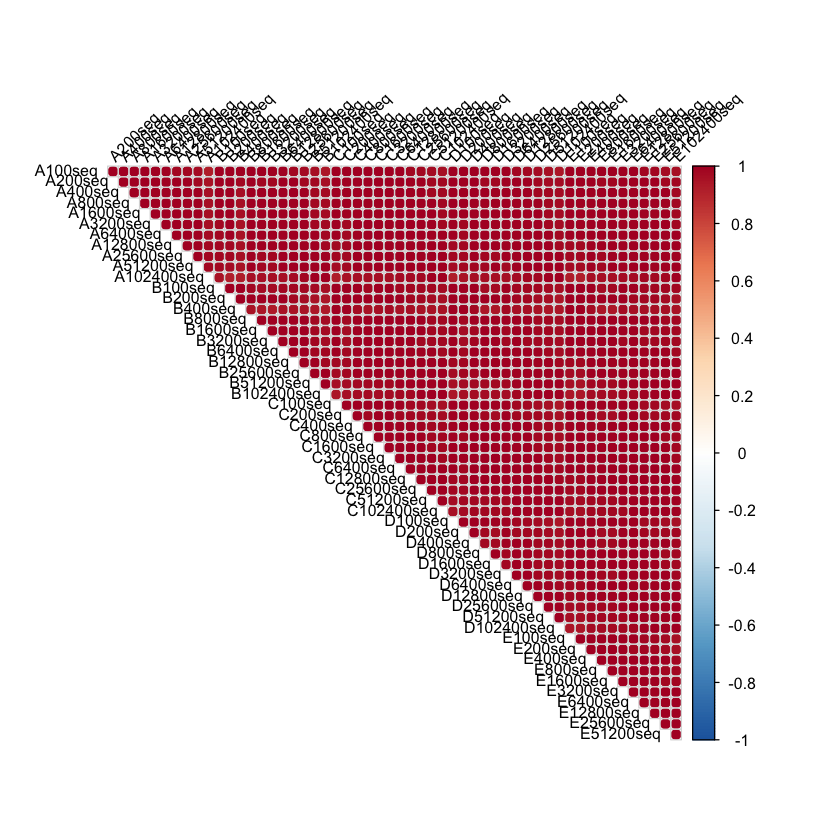

In [6]:

# CORRELOGRAMA DE PEARSON ENTRE MÉTRICAS DE DIVERSIDAD

library(tidyverse)
library(corrplot)

# 1. Leer matriz de diversidad
df <- read_tsv(
  "../results/diversity_matrix/diversity_matrix_A.tsv"
)

# 2. Convertir a matriz numérica
# Primera columna = métricas
mat <- df %>%
  column_to_rownames(var = names(df)[1]) %>%
  mutate(across(everything(), as.numeric)) %>%
  as.matrix()

# 3. Transponer para que las filas sean
# observaciones y las columnas sean métricas
mat_t <- t(mat)

# 4. Calcular correlación de Pearson
cor_pearson <- cor(
  mat_t,
  method = "pearson",
  use = "pairwise.complete.obs"
)

# 5. Graficar correlograma de círculos

corrplot(
  cor_pearson,
  method = "circle",
  type = "upper",
  order = "original",
  diag = FALSE,
  tl.col = "black",
  tl.srt = 45,
  tl.cex = 0.8,
  col = colorRampPalette(
    c("#2166AC", "#67A9CF", "#D1E5F0",
      "white",
      "#FDDDBC", "#EF8A62", "#B2182B")
  )(200),
  cl.lim = c(-1, 1),
  addgrid.col = "grey85"
)

# 6. Guardar matriz de correlaciones
write.csv(
  cor_pearson,
  "../results/correlacion_pearson.csv"
)
